# Spam Detection with Deep Learning - Exploration & Experiments

This notebook explores the **SMS Spam Collection** dataset, shows the preprocessing pipeline, and walks through training and evaluating the Embedding + Bidirectional LSTM model used in `train.py`.

> Run it from the `notebooks/` folder (VS Code does this automatically).

In [1]:
import sys, os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
sys.path.insert(0, os.path.abspath('..'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from src import config as C
from src.data_loader import load_dataset
from src.preprocessing import Vocabulary, clean_text
%matplotlib inline

## 1. Load the data

In [2]:
df = load_dataset()
print(df.shape)
df.head()

(5574, 2)


,label,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
df['label'].map({0: 'ham', 1: 'spam'}).value_counts()

label
ham     4827
spam     747
Name: count, dtype: int64

The dataset is **imbalanced** (about 13% spam), so accuracy alone is misleading. We therefore report precision, recall, F1 and ROC-AUC for the spam class and use class weights during training.

## 2. Exploratory data analysis

In [4]:
df['words'] = df['text'].str.split().str.len()
df['chars'] = df['text'].str.len()
df.groupby('label')[['words', 'chars']].mean().rename(index={0: 'ham', 1: 'spam'})

,words,chars
label,,
ham,14.304123,71.471929
spam,23.911647,138.676037


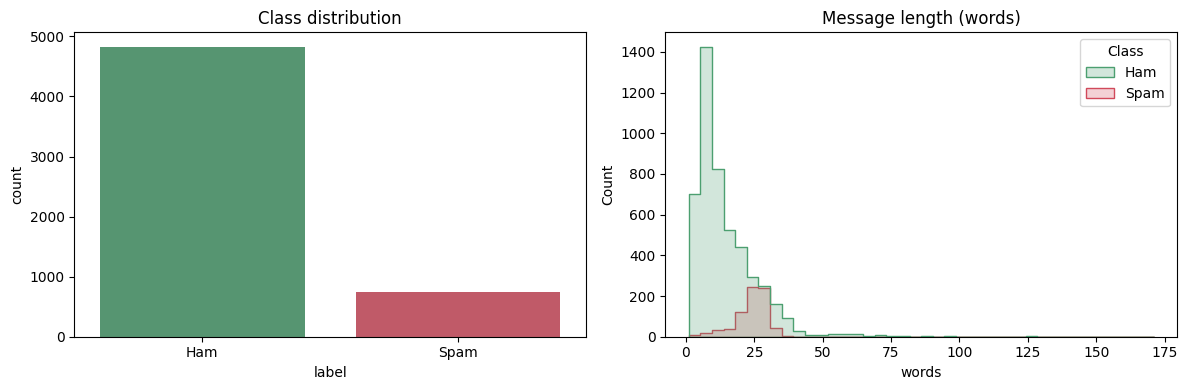

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=df['label'].map({0: 'Ham', 1: 'Spam'}), hue=df['label'].map({0: 'Ham', 1: 'Spam'}), palette={'Ham': '#4C9F70', 'Spam': '#D1495B'}, legend=False, ax=axes[0])
axes[0].set_title('Class distribution')
sns.histplot(data=df.assign(Class=df['label'].map({0: 'Ham', 1: 'Spam'})), x='words', hue='Class', bins=40, element='step', palette={'Ham': '#4C9F70', 'Spam': '#D1495B'}, ax=axes[1])
axes[1].set_title('Message length (words)')
plt.tight_layout(); plt.show()

Spam messages tend to be **longer** than ham messages and often contain numbers, phone numbers, and calls to action.

In [6]:
from collections import Counter
from src.preprocessing import tokenize
for lab, name in [(1, 'SPAM'), (0, 'HAM')]:
    c = Counter(w for t in df[df.label == lab]['text'] for w in tokenize(t) if len(w) > 2)
    print(name, c.most_common(15))

SPAM [('numtoken', 1439), ('phonetoken', 691), ('call', 370), ('you', 299), ('your', 264), ('free', 228), ('the', 206), ('for', 204), ('now', 203), ('txt', 165), ('have', 135), ('from', 132), ('mobile', 129), ('stop', 128), ('text', 125)]
HAM [('you', 1948), ('the', 1137), ('numtoken', 932), ('and', 858), ('that', 561), ('for', 507), ('have', 443), ('can', 441), ('but', 441), ('not', 421), ('your', 417), ('are', 415), ('will', 346), ('get', 311), ('how', 305)]


## 3. Preprocessing

In [7]:
sample = 'WINNER!! You won £1000. Call 09061701461 or visit http://claim-prize.com now!'
print(sample)
print(clean_text(sample))

WINNER!! You won £1000. Call 09061701461 or visit http://claim-prize.com now!
winner you won numtoken call phonetoken or visit urltoken now


In [8]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=C.SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=C.SEED)
vocab = Vocabulary.build(train_df['text'])
print('Vocabulary size:', len(vocab))
x_train, y_train = vocab.encode_batch(train_df['text']), train_df['label'].values
x_val, y_val = vocab.encode_batch(val_df['text']), val_df['label'].values
x_test, y_test = vocab.encode_batch(test_df['text']), test_df['label'].values
print(x_train.shape, x_val.shape, x_test.shape)

Vocabulary size: 6395
(3901, 50) (836, 50) (837, 50)


## 4. Build and train the neural network

In [9]:
from tensorflow import keras
from src.model import build_model
keras.utils.set_random_seed(C.SEED)
model = build_model(len(vocab))
model.summary()

I0000 00:00:1792770673.146239     365 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792770674.528208     365 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "spam_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │       409,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bi_lstm (Bidirectional)         │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spam_probability (Dense)        │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 479,489 (1.83 MB)

 Trainable params: 479,489 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
w = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=C.EPOCHS, batch_size=C.BATCH_SIZE,
                    class_weight={0: w[0], 1: w[1]},
                    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=C.EARLY_STOP_PATIENCE, restore_best_weights=True)],
                    verbose=2)

Epoch 1/20


E0000 00:00:1792770678.129151     365 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


122/122 - 7s - 61ms/step - accuracy: 0.8462 - loss: 0.3138 - precision: 0.4641 - recall: 0.9503 - val_accuracy: 0.9785 - val_loss: 0.1087 - val_precision: 0.8852 - val_recall: 0.9643


Epoch 2/20


122/122 - 5s - 37ms/step - accuracy: 0.9836 - loss: 0.0641 - precision: 0.9048 - recall: 0.9809 - val_accuracy: 0.9821 - val_loss: 0.0735 - val_precision: 0.8943 - val_recall: 0.9821


...

122/122 - 5s - 42ms/step - accuracy: 0.9990 - loss: 0.0033 - precision: 0.9924 - recall: 1.0000 - val_accuracy: 0.9880 - val_loss: 0.0559 - val_precision: 0.9474 - val_recall: 0.9643


Epoch 6/20


122/122 - 5s - 40ms/step - accuracy: 0.9995 - loss: 0.0017 - precision: 0.9962 - recall: 1.0000 - val_accuracy: 0.9880 - val_loss: 0.0601 - val_precision: 0.9474 - val_recall: 0.9643


Epoch 7/20


122/122 - 5s - 41ms/step - accuracy: 0.9995 - loss: 0.0012 - precision: 0.9962 - recall: 1.0000 - val_accuracy: 0.9880 - val_loss: 0.0629 - val_precision: 0.9474 - val_recall: 0.9643


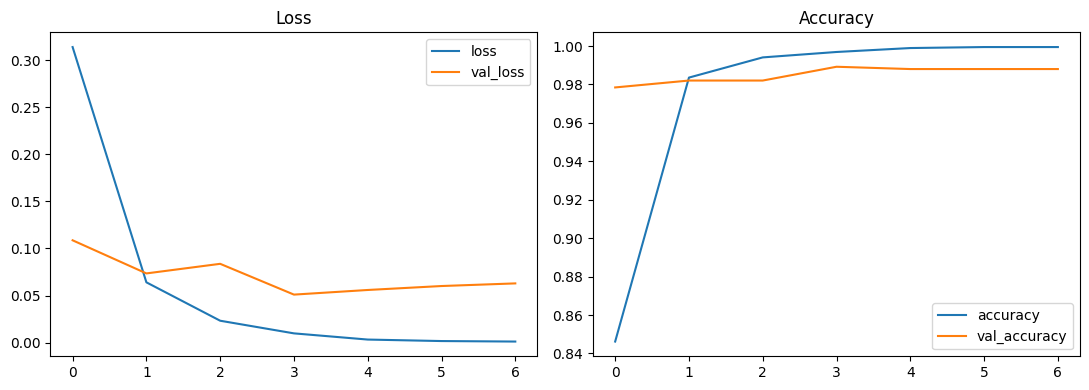

In [11]:
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hist[['loss', 'val_loss']].plot(ax=axes[0], title='Loss')
hist[['accuracy', 'val_accuracy']].plot(ax=axes[1], title='Accuracy')
plt.tight_layout(); plt.show()

## 5. Evaluation on the unseen test set

              precision    recall  f1-score   support

         Ham     0.9931    0.9890    0.9910       725
        Spam     0.9304    0.9554    0.9427       112

    accuracy                         0.9845       837
   macro avg     0.9618    0.9722    0.9669       837
weighted avg     0.9847    0.9845    0.9846       837



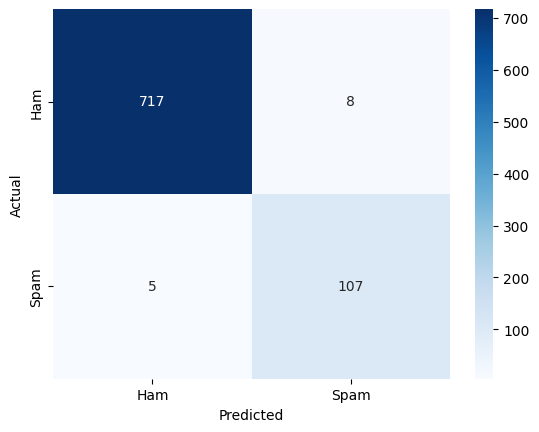

In [12]:
probs = model.predict(x_test, verbose=0).ravel()
y_pred = (probs >= 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam'], digits=4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

## 6. Experiment: effect of the decision threshold

Lowering the threshold catches more spam (higher recall) but may block more legitimate messages (lower precision).

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (probs >= t).astype(int)
    rows.append({'threshold': t, 'precision': precision_score(y_test, p), 'recall': recall_score(y_test, p), 'f1': f1_score(y_test, p)})
pd.DataFrame(rows).round(4)

,threshold,precision,recall,f1
0,0.3,0.8992,0.9554,0.9264
1,0.4,0.9145,0.9554,0.9345
2,0.5,0.9304,0.9554,0.9427
3,0.6,0.9386,0.9554,0.9469
4,0.7,0.9386,0.9554,0.9469
5,0.8,0.9630,0.9286,0.9455
6,0.9,0.9811,0.9286,0.9541


## 7. Try your own messages

In [14]:
def classify(text):
    p = float(model.predict(vocab.encode_batch([text]), verbose=0)[0][0])
    return ('SPAM' if p >= 0.5 else 'HAM'), round(p, 4)

for msg in ['Free entry! Text WIN to 80086 to claim your prize now',
            'Are you coming to the library at 5?',
            'URGENT: your bank account is locked, click http://secure-login.example']:
    print(classify(msg), '<-', msg)

('SPAM', 1.0) <- Free entry! Text WIN to 80086 to claim your prize now


('HAM', 0.0051) <- Are you coming to the library at 5?
('SPAM', 0.9748) <- URGENT: your bank account is locked, click http://secure-login.example


## Conclusion

The Embedding + Bidirectional LSTM reaches roughly 98% test accuracy with a spam F1-score around 0.94. Remaining errors are mostly very short, ambiguous messages. The final model used by the app is trained by `train.py`.